# CNN-LSTM SOH estimation with the original dataset features

This experiment uses the **original `train.csv`**, not `train_final_filtered.csv`.
All original exported training rows and SOH targets are retained before windowing;
rest-associated increases and fluctuations are not removed or smoothed.

Inputs are the dataset's five original charging features: `cc_duration_s`,
`cv_duration_s`, `dva_peak`, `ic_peak_voltage`, and `ic_peak_width`.
These are the original exported features, not newly extracted paper features or raw signals.
Standardization is fitted on training rows only. SOH stays fractional.

The model keeps the existing adapted parallel CNN (kernels 3, 5, 9) and
two-layer LSTM (256 units), with 12-cycle windows and seeds 42, 123, 2026.
Windows stay within one battery, consecutive original cycle ordinals and an
unchanged source identifier, with strictly increasing timestamps.
Validation selects each checkpoint; test data is used only for final evaluation.
Outputs are stored separately in `cnn_lstm_original_features_results`.


In [1]:
# Dependencies: numpy pandas torch matplotlib scikit-learn nbformat nbclient
# Install in your notebook kernel if needed: %pip install numpy pandas torch matplotlib scikit-learn

In [1]:
from pathlib import Path
import json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if not (ROOT / "pre processed ready to use data").exists():
    raise FileNotFoundError("Run this notebook from the Battery_Soh project root")
DATA_DIR = ROOT / "pre processed ready to use data"
OUTPUT_DIR = DATA_DIR.parent / "cnn_lstm_original_features_results"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
SEQ_LEN=12
EPOCHS=100
BATCH_SIZE=128
LR=1e-3
PATIENCE=15
SEEDS=[42,123,2026]
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
print('Device:', DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
for name in ['train.csv','validation.csv','test.csv']:
    assert (DATA_DIR/name).exists(), f'Missing {DATA_DIR/name}'


Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
train=pd.read_csv(DATA_DIR/'train.csv')
val=pd.read_csv(DATA_DIR/'validation.csv')
test=pd.read_csv(DATA_DIR/'test.csv')
for frame, name in [(train,'train'),(val,'validation'),(test,'test')]:
    missing=set(FEATURES+['battery','cycle_ordinal','cycle_start','source_identifiers',TARGET])-set(frame.columns)
    if missing: raise ValueError(f'{name} missing columns: {missing}')
    if not np.isfinite(frame[FEATURES+[TARGET]].to_numpy(dtype=float)).all(): raise ValueError(f'{name} contains missing inputs or targets')
    if frame.duplicated(['battery','cycle_ordinal']).any(): raise ValueError(f'{name} has duplicate battery/cycle IDs')
    print(name, frame.shape, sorted(frame.battery.unique()))
assert set(train.battery).isdisjoint(val.battery)
assert set(train.battery).isdisjoint(test.battery)
assert set(val.battery).isdisjoint(test.battery)

scaler=StandardScaler().fit(train[FEATURES].to_numpy(dtype=np.float64))
with open(OUTPUT_DIR/'scaler.json','w') as f:
    json.dump({'features':FEATURES,'mean':scaler.mean_.tolist(),'scale':scaler.scale_.tolist()},f,indent=2)


train (7790, 13) ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation (1743, 13) ['CX2_36']
test (1477, 13) ['CX2_38']


In [4]:
def make_windows(frame, seq_len=SEQ_LEN):
    xs,ys,meta=[],[],[]
    for battery, part in frame.groupby('battery'):
        part=part.sort_values('cycle_ordinal').reset_index(drop=True)
        cycles=part.cycle_ordinal.to_numpy()
        values=scaler.transform(part[FEATURES].to_numpy(dtype=np.float64)).astype(np.float32)
        targets=part[TARGET].to_numpy(dtype=np.float32)
        # Divide into maximal uninterrupted runs of consecutive ordinal IDs
        times=pd.to_datetime(part.cycle_start, errors='raise')
        if times.isna().any() or part.source_identifiers.isna().any():
            raise ValueError('Missing acquisition metadata')
        source=part.source_identifiers.to_numpy()
        breaks=(np.diff(cycles)!=1) | (source[1:]!=source[:-1]) | (np.diff(times.to_numpy())<=np.timedelta64(0,'s'))
        boundaries=np.r_[0, np.flatnonzero(breaks)+1, len(part)]
        for a,z in zip(boundaries[:-1],boundaries[1:]):
            for end in range(a+seq_len-1,z):
                start=end-seq_len+1
                xs.append(values[start:end+1]); ys.append(targets[end])
                meta.append({'battery':battery,'cycle_ordinal':int(cycles[end]),'soh':float(targets[end]),'cycle_start':str(part.cycle_start.iloc[end]),'window_start_cycle':int(cycles[start])})
    if not xs: raise ValueError('No full contiguous windows. Reduce SEQ_LEN or inspect cycle ordinals.')
    return np.stack(xs),np.array(ys,dtype=np.float32),pd.DataFrame(meta)

Xtr,ytr,mtr=make_windows(train)
Xva,yva,mva=make_windows(val)
Xte,yte,mte=make_windows(test)
print('Window counts:',len(ytr),len(yva),len(yte),'Shape:',Xtr.shape)
print('Excluded from evaluation due to warm-up or gaps:',len(test)-len(yte))


Window counts: 3639 848 662 Shape: (3639, 12, 5)
Excluded from evaluation due to warm-up or gaps: 815


## Adapted architecture
Three **parallel same-padded Conv1d branches** with temporal kernels 3, 5, 9; concatenation → 2-layer LSTM (hidden 256) → dropout → linear regression head. Parallel filters are an engineering choice for the five-feature cycle windows; the paper's diagram and convolution dimensional notation do not establish this exact topology.

In [5]:
class PaperInspiredCNNLSTM(nn.Module):
    def __init__(self,n_features=5,branch_channels=32,hidden=256,dropout=0.2):
        super().__init__()
        self.branches=nn.ModuleList([
            nn.Sequential(nn.Conv1d(n_features,branch_channels,kernel_size=k,padding=k//2),nn.ReLU())
            for k in (3,5,9)
        ])
        self.lstm=nn.LSTM(input_size=branch_channels*3,hidden_size=hidden,
                          num_layers=2,dropout=dropout,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,x): # (batch,cycles,features)
        z=x.transpose(1,2)
        z=torch.cat([branch(z) for branch in self.branches],dim=1)
        z=z.transpose(1,2)
        z,_=self.lstm(z)
        return self.head(z[:,-1,:]).squeeze(-1)

model=PaperInspiredCNNLSTM().to(DEVICE)
print('Parameters:',sum(p.numel() for p in model.parameters()))
print('Example output:',model(torch.from_numpy(Xtr[:2]).to(DEVICE)).shape)


Parameters: 891905


Example output: torch.Size([2])


In [2]:
def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'mae_pp':float(mean_absolute_error(y,p)*100),
            'rmse_pp':float(np.sqrt(mean_squared_error(y,p))*100),
            'mbe_pp':float(np.mean(p-y)*100),
            'mape_percent':float(np.mean(np.abs((p-y)/np.maximum(np.abs(y),1e-8)))*100),
            'r2':float(r2_score(y,p))}

def predict(model,X,batch=512):
    model.eval(); out=[]
    loader=DataLoader(torch.from_numpy(X),batch_size=batch)
    with torch.no_grad():
        for xx in loader: out.append(model(xx.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_one(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    net=PaperInspiredCNNLSTM(n_features=len(FEATURES)).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    loss_fn=nn.MSELoss()
    loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),
                      batch_size=BATCH_SIZE,shuffle=True)
    best=float('inf');best_state=None;bad=0;history=[];start=time.time()
    for epoch in range(1,EPOCHS+1):
        net.train();total=0.;count=0
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=loss_fn(net(xb),yb)
            loss.backward();torch.nn.utils.clip_grad_norm_(net.parameters(),1.0)
            opt.step();total+=loss.item()*len(yb);count+=len(yb)
        val_pred=predict(net,Xva)
        val_mse=float(np.mean((val_pred-yva)**2))
        print(f'Seed {seed} epoch {epoch} validation RMSE {np.sqrt(val_mse)*100:.4f} pp', flush=True)
        history.append({'epoch':epoch,'train_mse':total/count,'val_mse':val_mse})
        if val_mse<best-1e-8:
            best=val_mse;best_state=copy.deepcopy(net.state_dict());bad=0
        else:bad+=1
        if epoch==1 or epoch%10==0 or bad>=PATIENCE:
            print(f'Seed {seed} epoch {epoch:3d} train MSE {total/count:.6f} val MSE {val_mse:.6f}')
        if bad>=PATIENCE:break
    net.load_state_dict(best_state)
    torch.save({'model_state':net.state_dict(),'features':FEATURES,'seq_len':SEQ_LEN,
                'seed':seed,'architecture':'adapted parallel CNN LSTM','scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),'best_epoch':int(np.argmin([h['val_mse'] for h in history])+1)},OUTPUT_DIR/f'cnn_lstm_seed{seed}.pt')
    pd.DataFrame(history).to_csv(OUTPUT_DIR/f'history_seed{seed}.csv',index=False)
    rows=[]
    for split,X,y,meta in [('train',Xtr,ytr,mtr),('validation',Xva,yva,mva),('test',Xte,yte,mte)]:
        pred=predict(net,X);out=meta.copy();out['prediction']=pred;out['error']=pred-y
        out.to_csv(OUTPUT_DIR/f'predictions_{split}_seed{seed}.csv',index=False)
        rows.append({'seed':seed,'split':split,'epochs':len(history),
                     'training_seconds':round(time.time()-start,2),**metrics(y,pred)})
    return rows,history


In [7]:
all_rows=[]; histories={}
for seed in SEEDS:
    rows,hist=train_one(seed)
    all_rows.extend(rows);histories[seed]=hist
results=pd.DataFrame(all_rows)
results.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
display(results.round(4))
summary=results.groupby('split')[['mae_pp','rmse_pp','mbe_pp','mape_percent','r2']].agg(['mean','std'])
summary.to_csv(OUTPUT_DIR/'metrics_summary.csv')
display(summary.round(4))


Seed 42 epoch 1 validation RMSE 3.3140 pp


Seed 42 epoch   1 train MSE 0.068090 val MSE 0.001098


Seed 42 epoch 2 validation RMSE 2.4804 pp


Seed 42 epoch 3 validation RMSE 1.8541 pp


Seed 42 epoch 4 validation RMSE 1.3642 pp


Seed 42 epoch 5 validation RMSE 1.2118 pp


... (162 outputs left out)

Seed 2026 epoch 54 validation RMSE 1.6180 pp


Seed 2026 epoch  54 train MSE 0.000536 val MSE 0.000262


,seed,split,epochs,training_seconds,mae_pp,rmse_pp,mbe_pp,mape_percent,r2
0,42,train,41,36.73,0.8739,1.1044,-0.8314,1.1736,0.9896
1,42,validation,41,36.76,0.6276,0.7881,-0.2388,0.8723,0.9958
2,42,test,41,36.82,0.8373,1.0181,0.7675,1.0831,0.9935
3,123,train,55,22.78,0.7723,0.9479,-0.6592,1.0566,0.9923
4,123,validation,55,22.83,0.6647,0.8788,0.0269,0.9588,0.9947
5,123,test,55,22.86,0.9459,1.1101,0.9309,1.2566,0.9922
6,2026,train,54,24.07,0.7821,0.9879,-0.6646,1.0774,0.9916
7,2026,validation,54,24.23,0.5988,0.7570,-0.0499,0.8347,0.9961
8,2026,test,54,24.27,0.7678,0.9049,0.7388,0.9938,0.9948


mae_pp         rmse_pp          mbe_pp         mape_percent  \
              mean     std    mean     std    mean     std         mean   
split                                                                     
test        0.8503  0.0898  1.0110  0.1028  0.8124  0.1036       1.1112   
train       0.8094  0.0560  1.0134  0.0813 -0.7184  0.0979       1.1025   
validation  0.6304  0.0331  0.8080  0.0633 -0.0873  0.1367       0.8886   

                        r2          
               std    mean     std  
split                               
test        0.1336  0.9935  0.0013  
train       0.0624  0.9912  0.0014  
validation  0.0636  0.9955  0.0007

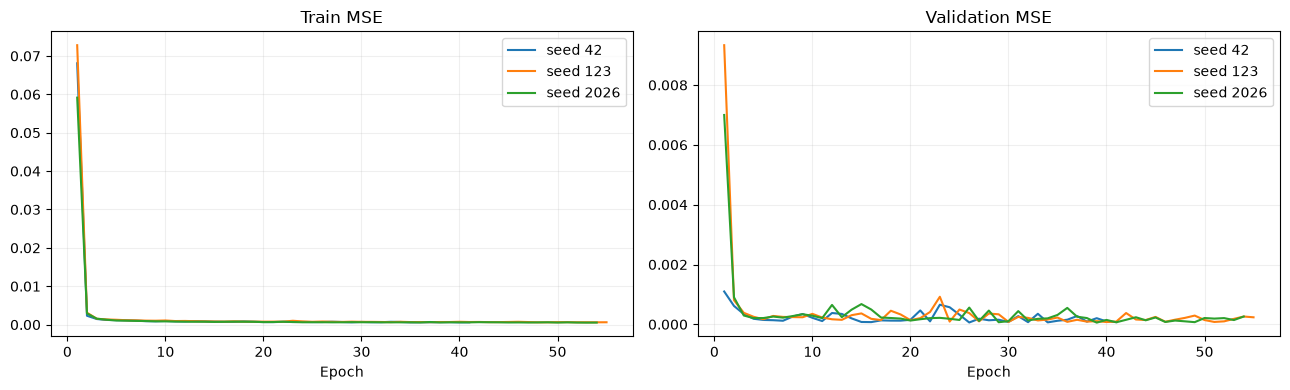

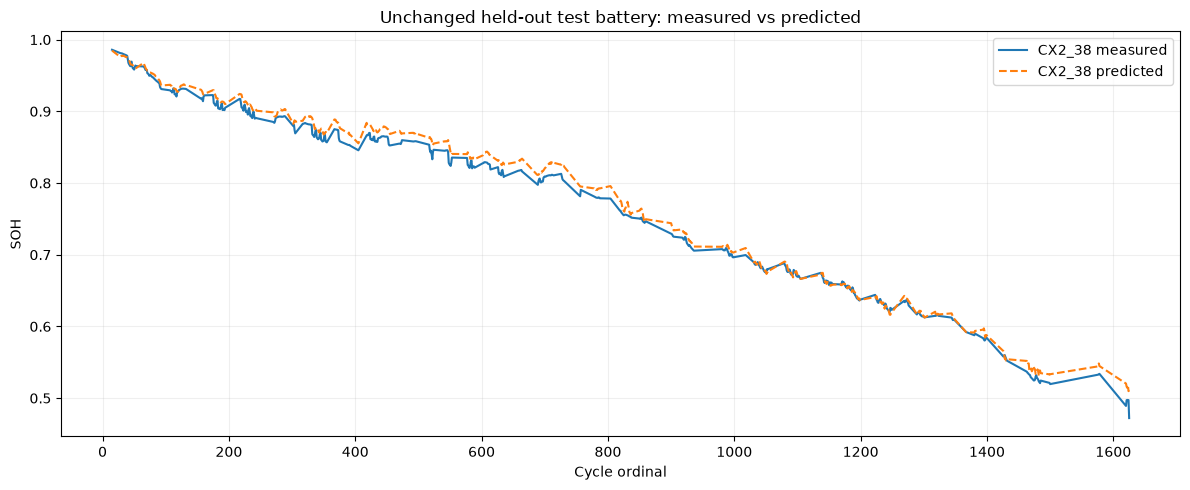

Saved to: C:\Projects\Battery_Soh\cnn_lstm_original_features_results


In [8]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for seed,h in histories.items():
    d=pd.DataFrame(h)
    axs[0].plot(d.epoch,d.train_mse,label=f'seed {seed}')
    axs[1].plot(d.epoch,d.val_mse,label=f'seed {seed}')
for ax,title in zip(axs,['Train MSE','Validation MSE']):
    ax.set_title(title);ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'learning_curves.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(12,5))
res=pd.read_csv(OUTPUT_DIR/'predictions_test_seed42.csv')
for battery,g in res.groupby('battery'):
    g=g.sort_values('cycle_ordinal')
    ax.plot(g.cycle_ordinal,g.soh,label=f'{battery} measured')
    ax.plot(g.cycle_ordinal,g.prediction,'--',label=f'{battery} predicted')
ax.set(xlabel='Cycle ordinal',ylabel='SOH',title='Unchanged held-out test battery: measured vs predicted')
ax.grid(alpha=.2);ax.legend();plt.tight_layout()
plt.savefig(OUTPUT_DIR/'test_predictions.png',dpi=160);plt.show()
print('Saved to:',OUTPUT_DIR)


## Interpretation
- MAE, RMSE and bias are SOH percentage points; MAPE is relative percent.
- Original dataset values are retained. No SOH-jump filtering, target smoothing or clipping is applied.
- The five exported charging features differ from the paper's features; this is an adapted CNN-LSTM baseline.
- Current-cycle charging features estimate current-cycle SOH, not future SOH.
- Window warm-up and acquisition boundaries exclude some target rows. Predictions include target IDs for matched comparisons.
- Each seed uses its best validation checkpoint. Test metrics are descriptive and do not select seeds.
